<a href="https://colab.research.google.com/github/f26-sjsu-cmpe188/CA9/blob/main/Digits_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Thien Doan

SJSU ID: 018793021

github


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
train_digits = []
with open('/content/drive/MyDrive/ZipDigits.train') as fp:
    for line in fp:
        train_digits.append([float(x) for x in line.split()])

train_digits = np.array(train_digits)


In [4]:
train_digits.shape

(7291, 257)

In [5]:
def print_digit(digit_row):
    digit_row = digit_row[1:257]
    digit_row = digit_row.reshape(16, 16)
    digit_row = (digit_row + 1)/2
    plt.imshow(digit_row, cmap='gray', vmin=0, vmax=1)


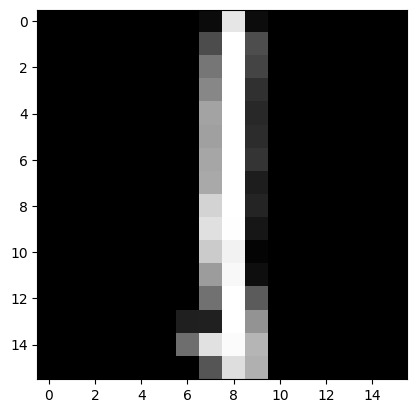

In [6]:
print_digit(train_digits[9])

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

In [8]:
# 1. Preprocess the dataset
# First column is the label, columns 1 to 256 are the 16x16 pixel values
X = train_digits[:, 1:257].reshape(-1, 16, 16, 1)
# Normalize pixels from [-1, 1] to [0, 1] range
X = (X + 1.0) / 2.0
y = train_digits[:, 0].astype(int)

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


In [30]:
# 2. Build a basic 8-layer CNN Architecture
# We will stack Conv2D, Activation, BatchNormalization, MaxPooling, and Dense layers
model = models.Sequential([
    # Layer 1: Conv2D
    layers.Conv2D(16, (3, 3), padding='same', input_shape=(16, 16, 1), name='conv_1'),
    layers.BatchNormalization(name='bn_1'),
    layers.Activation('relu', name='relu_1'),

    # Layer 2: Conv2D
    layers.Conv2D(32, (3, 3), padding='same', name='conv_2'),
    layers.BatchNormalization(name='bn_2'),
    layers.Activation('relu', name='relu_2'),
    layers.MaxPooling2D((2, 2), name='pool_1'), # Downsample to 8x8

    # Layer 3: Conv2D
    layers.Conv2D(32, (3, 3), padding='same', name='conv_3'),
    layers.BatchNormalization(name='bn_3'),
    layers.Activation('relu', name='relu_3'),
    layers.MaxPooling2D((2, 2), name='pool_2'), # Downsample to 4x4

    # Flatten and Dense layers to complete the classification head
    layers.Flatten(name='flatten'),

    # Layer 4: Dense
    layers.Dense(128, name='fc_1'),
    layers.BatchNormalization(name='bn_4'),
    layers.Activation('relu', name='relu_4'),
    layers.Dropout(0.3, name='dropout_1'),

    # Layer 5: Dense output
    layers.Dense(10, activation='softmax', name='output')
])


In [31]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 16, 16, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 16, 16, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 16, 16, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 8, 8, 32)       │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (Activation)             │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_1 (Dense)                    │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_4 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_4 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,834 (319.66 KB)

 Trainable params: 81,418 (318.04 KB)

 Non-trainable params: 416 (1.62 KB)

Original:  Total params: 156,746 (612.29 KB)

Cut half in layer 2:  Total params: 145,146 (566.98 KB)

Cut half in layer 3: Total params: 81,834 (319.66 KB)

Reducing the number of filters in Layer 3 by half reduces the number of parameters in Layer 3 and the following layer. However, the total number of learnable parameters in the CNN may not be reduced by exactly half because the result depends on the size and structure of the other layers.

In [11]:
# 3. Train the model for 20 epochs
print("Training the CNN model...")
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_val, y_val), batch_size=64)


Training the CNN model...
Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.8812 - loss: 0.4393 - val_accuracy: 0.1467 - val_loss: 2.1904
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.9741 - loss: 0.1134 - val_accuracy: 0.2330 - val_loss: 2.0725
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - accuracy: 0.9846 - loss: 0.0663 - val_accuracy: 0.6799 - val_loss: 0.9430
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9899 - loss: 0.0440 - val_accuracy: 0.9040 - val_loss: 0.3335
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.9942 - loss: 0.0351 - val_accuracy: 0.9733 - val_loss: 0.1148
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.9954 - loss: 0.0264 - val_accuracy: 0.9829 - val_loss: 0.0669
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.9979 - loss: 0.0186 - val_accuracy: 0.9788 - val_loss: 0.0680
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.9983 - loss: 0.013

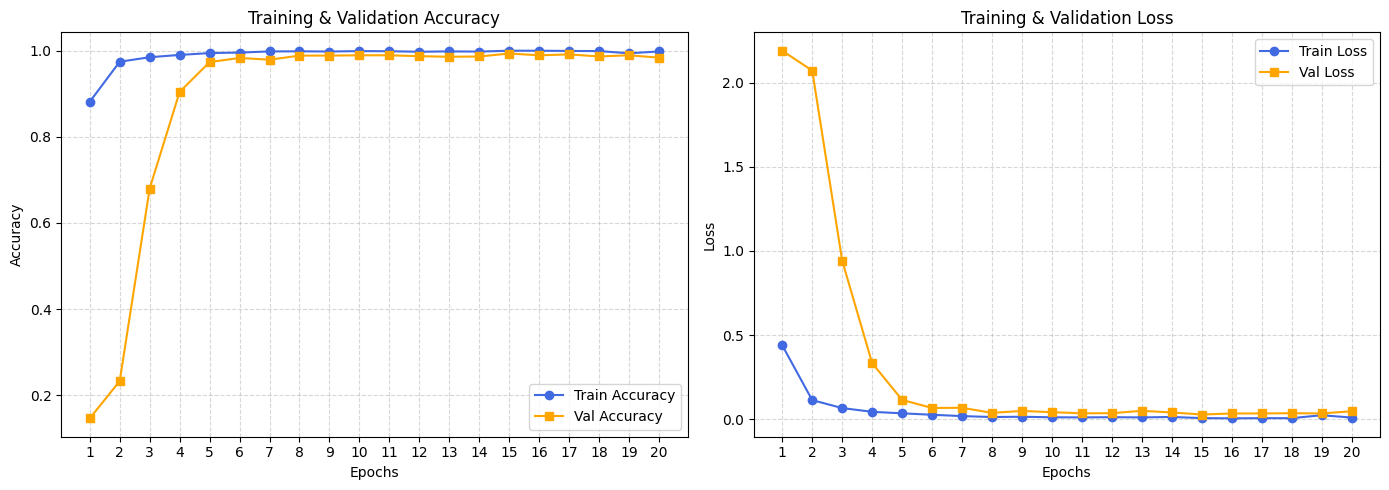

In [12]:
# Plot the training and validation accuracy and loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Accuracy Plot
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='royalblue', marker='o')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', marker='s')
ax1.set_title('Training & Validation Accuracy')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.set_xticks(range(len(history.history['accuracy'])))
ax1.set_xticklabels(range(1, len(history.history['accuracy']) + 1))
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Loss Plot
ax2.plot(history.history['loss'], label='Train Loss', color='royalblue', marker='o')
ax2.plot(history.history['val_loss'], label='Val Loss', color='orange', marker='s')
ax2.set_title('Training & Validation Loss')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.set_xticks(range(len(history.history['loss'])))
ax2.set_xticklabels(range(1, len(history.history['loss']) + 1))
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [13]:
def plot_filters_and_outputs(layer_to_visualize, sample_index):
  # Extract weights (filters) of the selected layer
  selected_layer = model.get_layer(layer_to_visualize)
  weights, biases = selected_layer.get_weights()

  # --- 1. PLOT FILTERS (WEIGHTS) ---
  num_filters = min(weights.shape[-1], 16)
  col_w = 8
  row_w = (num_filters + col_w - 1) // col_w

  fig, axes = plt.subplots(row_w, col_w, figsize=(16, 1.7 * row_w + 1))
  fig.suptitle(f"Filters (Weights) for Layer: {layer_to_visualize}", fontsize=14, y=1.05)

  w_slice = weights[:, :, 0, :num_filters]
  w_limit = np.max(np.abs(w_slice))

  im_w = None
  for i in range(row_w * col_w):
      r_idx = i // col_w
      c_idx = i % col_w
      ax = axes[r_idx, c_idx] if row_w > 1 else axes[c_idx]

      if i < num_filters:
          filt = weights[:, :, 0, i]
          im_w = ax.imshow(filt, cmap='RdBu_r', vmin=-w_limit, vmax=w_limit)
          ax.set_title(f"Filter {i}", fontsize=9)
      ax.axis('off')

  # Add a single shared colorbar for the filters
  if im_w is not None:
      fig.subplots_adjust(right=0.9)
      cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
      fig.colorbar(im_w, cax=cbar_ax, label='Weight Value')

  plt.show()

  # --- 2. PLOT LAYER ACTIVATIONS (OUTPUTS) ---
  activation_model = models.Model(inputs=model.inputs, outputs=selected_layer.output)
  sample_img = X_val[sample_index:sample_index+1]
  activations = activation_model([sample_img], training=False).numpy()

  # Display original image
  plt.figure(figsize=(2.2, 2.2))
  plt.title(f"Original Digit (Label: {y_val[sample_index]})")
  plt.imshow(sample_img[0, :, :, 0], cmap='gray')
  plt.axis('off')
  plt.show()

  # Display activation feature maps
  num_features = min(activations.shape[-1], 16)
  col_a = 8
  row_a = (num_features + col_a - 1) // col_a

  fig, axes = plt.subplots(row_a, col_a, figsize=(16, 2.0 * row_a + 1))
  fig.suptitle(f"Feature Maps (Outputs) for Layer: {layer_to_visualize}", fontsize=14, y=1.05)

  act_slice = activations[0, :, :, :num_features]
  a_min, a_max = act_slice.min(), act_slice.max()

  im_a = None
  for i in range(row_a * col_a):
      r_idx = i // col_a
      c_idx = i % col_a
      ax = axes[r_idx, c_idx] if row_a > 1 else axes[c_idx]

      if i < num_features:
          feat = activations[0, :, :, i]
          im_a = ax.imshow(feat, cmap='viridis', vmin=a_min, vmax=a_max)
          ax.set_title(f"Map {i}", fontsize=9)
      ax.axis('off')

  # Add a single shared colorbar for the activations
  if im_a is not None:
      fig.subplots_adjust(right=0.9)
      cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
      fig.colorbar(im_a, cax=cbar_ax, label='Activation Level')

  plt.show()

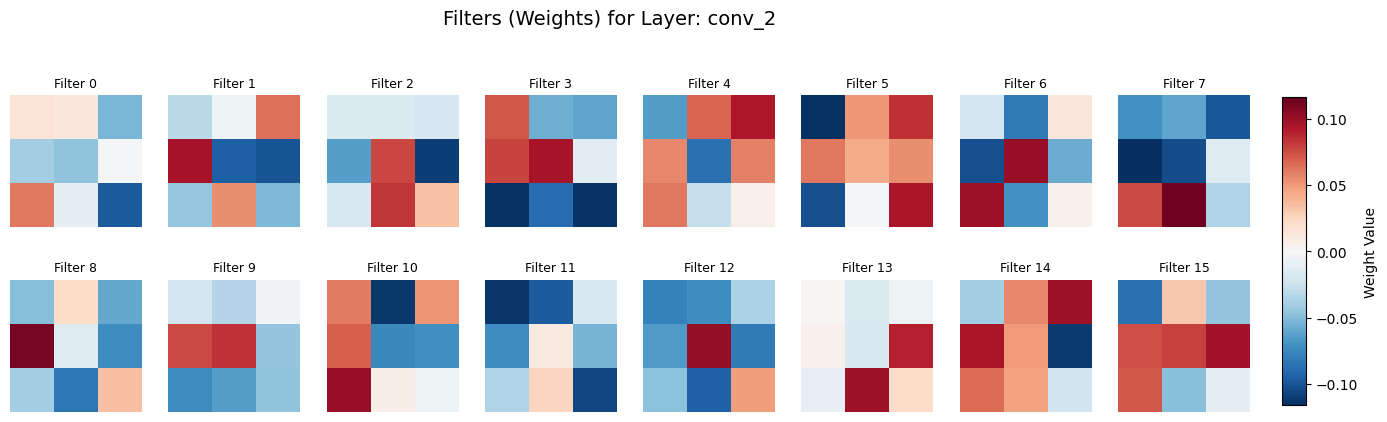

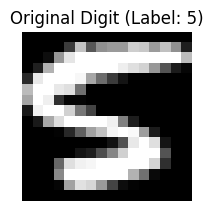

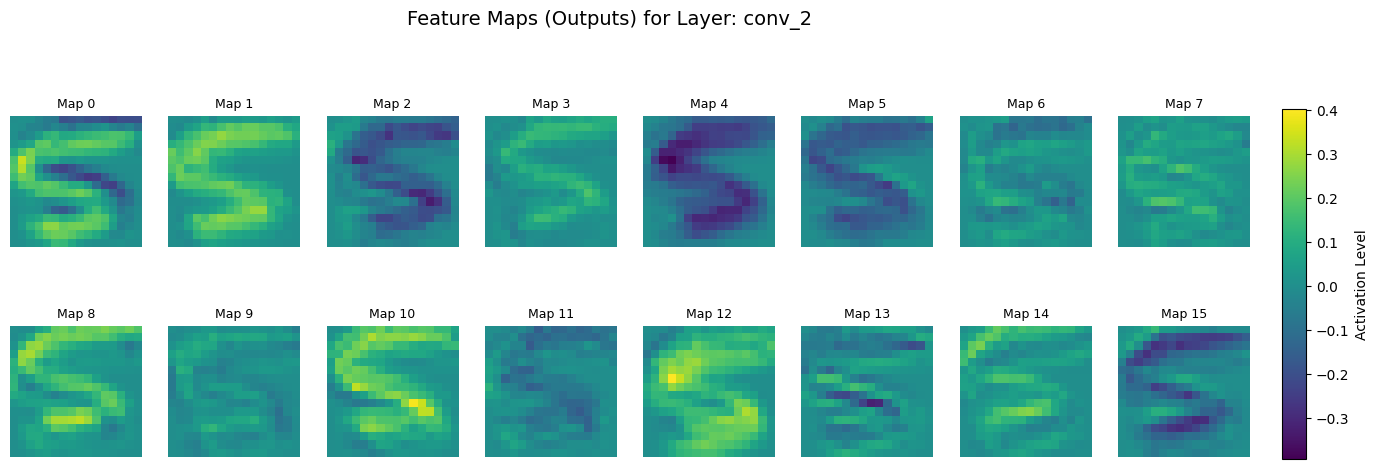

In [44]:
# 4. Plots of the filters and outputs of a given layer
layer_to_visualize = 'conv_2'  # Try changing this to 'conv_2' or 'conv_3'
sample_index = 5               # Index of the validation image to visualize
# ----------------------------------

plot_filters_and_outputs(layer_to_visualize, sample_index)

The CNN can detect simple features that humans can understand, such as lines, curves, and edges. The bright areas in the feature maps show where the CNN found these features. This is similar to how humans recognize a digit by looking at its shape and curves. However, the CNN uses numerical patterns, so it does not understand the digit exactly like a human.

In [15]:
test_digits = []
with open('/content/drive/MyDrive/ZipDigits.test') as fp:
    for line in fp:
        test_digits.append([float(x) for x in line.split()])

test_digits = np.array(test_digits)
print(f"Test set loaded. Shape: {test_digits.shape}")

Test set loaded. Shape: (2007, 257)


In [16]:
X_test = test_digits[:, 1:257].reshape(-1, 16, 16, 1)
X_test = (X_test + 1.0) / 2.0
y_test = test_digits[:, 0].astype(int)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=1)
print(f"\nTest Loss: {test_loss:.2f}")
print(f"Test Accuracy: {test_acc:.2%}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9676 - loss: 0.1561

Test Loss: 0.16
Test Accuracy: 96.76%


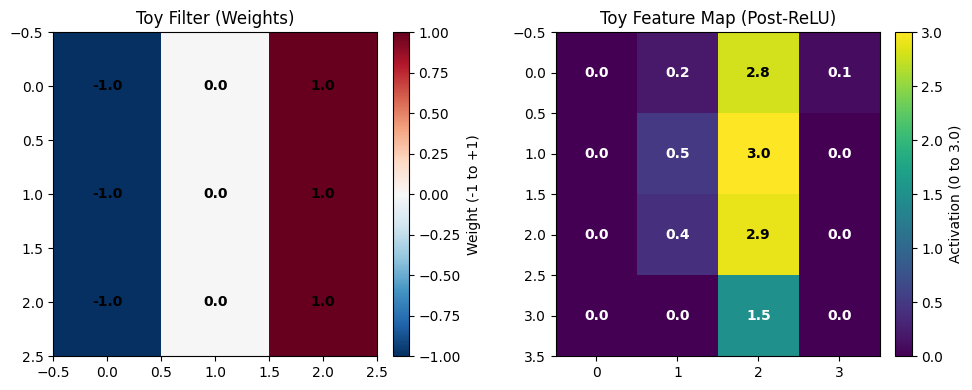

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Toy 3x3 vertical edge filter (negative on left, positive on right)
toy_filter = np.array([
    [-1.0, 0.0, 1.0],
    [-1.0, 0.0, 1.0],
    [-1.0, 0.0, 1.0]
])

# Toy 4x4 post-ReLU feature map (0 = no match, higher = stronger edge match)
toy_activation = np.array([
    [0.0, 0.2, 2.8, 0.1],
    [0.0, 0.5, 3.0, 0.0],
    [0.0, 0.4, 2.9, 0.0],
    [0.0, 0.0, 1.5, 0.0]
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# 1. Plot Toy Filter
im1 = ax1.imshow(toy_filter, cmap='RdBu_r', vmin=-1, vmax=1)
ax1.set_title("Toy Filter (Weights)")
for (r, c), val in np.ndenumerate(toy_filter):
    ax1.text(c, r, f"{val:.1f}", ha='center', va='center', color='black', fontweight='bold')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="Weight (-1 to +1)")

# 2. Plot Toy Activation
im2 = ax2.imshow(toy_activation, cmap='viridis', vmin=0, vmax=3)
ax2.set_title("Toy Feature Map (Post-ReLU)")
for (r, c), val in np.ndenumerate(toy_activation):
    # Switch text color to black on bright yellow squares for readability
    txt_color = 'black' if val > 1.8 else 'white'
    ax2.text(c, r, f"{val:.1f}", ha='center', va='center', color=txt_color, fontweight='bold')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="Activation (0 to 3.0)")

plt.tight_layout()
plt.show()
